In [ ]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay,
)

from data_engineering import make_splits, load_raw, clean, build_features


In [ ]:
# Cargar datines
df = clean(raw_data)
out = make_splits(df)

# Comprobamos
data = []
for ts, (X_tr, X_te, y_tr, y_te, info) in out.items():
        data.append((ts, X_tr, X_te, y_tr, y_te, info))
        print(f"test={ts:.0%} -> train {X_tr.shape}, test {X_te.shape}, "
              f"%>50K train={y_tr.mean():.3f} test={y_te.mean():.3f}")

test=10% -> train (43911, 88), test (4879, 88), %>50K train=0.239 test=0.239
test=20% -> train (39032, 88), test (9758, 88), %>50K train=0.239 test=0.239
test=30% -> train (34153, 88), test (14637, 88), %>50K train=0.239 test=0.239
test=40% -> train (29274, 88), test (19516, 88), %>50K train=0.239 test=0.239


In [6]:
def relu(matr):
    return np.maximum(0, matr) #deja los negativos en 0 y no molesta positivos


def relu_derivative(matr):
    return (matr > 0).astype(float) #pendiente local de relu pal descenso de gradiente


def sigmoid(matr): #numeros into probabilidad con la funcion sigmoide
    matr = np.clip(matr, -500, 500) #limites pa evitar desbordamientos 
    return 1 / (1 + np.exp(-matr))


def BCE(Y, Y_HAT): #funcion d perdida
    eps = 1e-12
    Y_HAT = np.clip(Y_HAT, eps, 1 - eps)
    N = len(Y)
    return -1 / N * np.sum(Y * np.log(Y_HAT) + (1 - Y) * np.log(1 - Y_HAT))

In [9]:
# 88 -> 88 -> 1
def forward(X, W1, b1, W2, b2):
    # capa oculta (N neuronas = N entradas)
    # multiplica matriz de entrada por pesos y aplica relu pa quitar negativos y producir activaciones
    # de la capa oculta
    matr1 = np.dot(X, W1) + b1
    A1 = relu(matr1)

    # capa de salida (1 miserable neurona)
    # COn las activaciones ocultas las mueltiplica por el vector col de pesos y suma escalar
    # Eso da los logits y esos se los vuelve prob con la sigmoide
    matr2 = np.dot(A1, W2) + b2
    A2 = sigmoid(matr2)

    return matr1, A1, matr2, A2

def backpropagation(X, Y, matr1, A1, A2, W1, b1, W2, b2, alpha):
    m = X.shape[0]

    # Gradientes capa de salida
    dZ2 = A2 - Y # error directo en la salida, solo queda diferencia entre predicha y etiq real
    dW2 = (A1.T @ dZ2) / m #gradiente promedio de cada peso de salida
    db2 = np.sum(dZ2, axis=0, keepdims=True) / m #promedio de error

    # Gradientes capa oculta (usa matr1 para evaluar la derivada de ReLU)
    dZ1 = (dZ2 @ W2.T) * relu_derivative(matr1) #propaga el error y lo reparte entre las 88 ocultas
    dW1 = (X.T @ dZ1) / m 
    db1 = np.sum(dZ1, axis=0, keepdims=True) / m #promedia gradientes por columna

    # Actualización de pesos y sesgos
    W2 -= alpha * dW2
    b2 -= alpha * db2
    W1 -= alpha * dW1
    b1 -= alpha * db1

    return W1, b1, W2, b2


In [10]:
def train(split, epochs=1000, alpha=0.05):
    rng = np.random.default_rng(42) #numeros aleatorios semilla fija
    X = split[1].to_numpy()
    Y = split[3].to_numpy().reshape(-1, 1)

    # Número de neuronas en la capa oculta = número de entradas (N)
    n_inputs = X.shape[1]
    h1 = n_inputs #fihjamos ocultas a numero de entradas

    # Inicialización He para ReLU y Xavier para Sigmoid; sesgos en cero
    W1 = rng.standard_normal((n_inputs, h1)) * np.sqrt(2 / n_inputs) #Aqui tira hehe hehe
    b1 = np.zeros((1, h1)) #88 sesgos en 0.0

    W2 = rng.standard_normal((h1, 1)) * np.sqrt(1 / h1) #Aqui es la javier
    b2 = np.zeros((1, 1)) #el unico sesgo de la neurona de salida en 0.0

    history = []
    for epoch in range(epochs):
        matr1, A1, matr2, A2 = forward(X, W1, b1, W2, b2)
        loss = BCE(Y, A2)
        W1, b1, W2, b2 = backpropagation(X, Y, matr1, A1, A2, W1, b1, W2, b2, alpha)
        history.append(loss)

    return W1, b1, W2, b2, history

Final train loss: 0.3329
ROC-AUC: 0.9003
              precision    recall  f1-score   support

       <=50K       0.88      0.92      0.90      7422
        >50K       0.71      0.60      0.65      2336

    accuracy                           0.85      9758
   macro avg       0.80      0.76      0.78      9758
weighted avg       0.84      0.85      0.84      9758



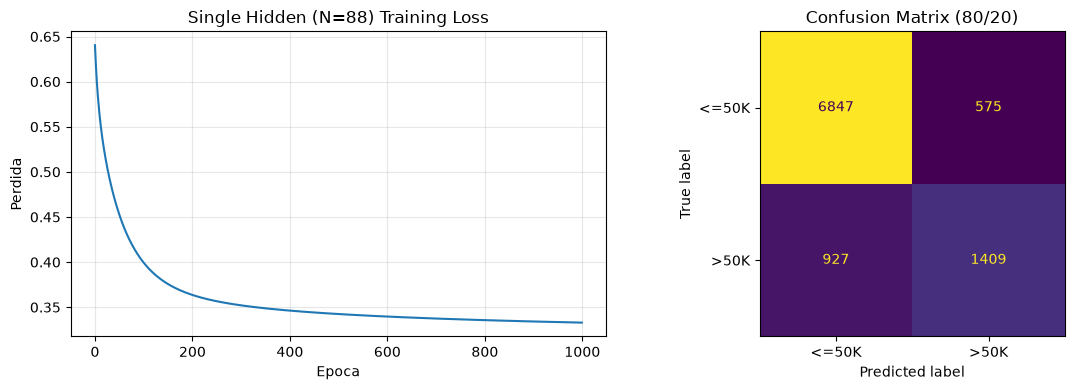

In [13]:
W1, b1, W2, b2, history = train(data[1], epochs=1000, alpha=0.05)
model = (W1, b1, W2, b2)

X_test = data[1][2].to_numpy()
y_test = data[1][4].to_numpy()

*_, probabilities = forward(X_test, *model)
probabilities = probabilities.ravel()
y_pred = (probabilities >= 0.5).astype(int)

print(f"Final train loss: {history[-1]:.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, probabilities):.4f}")
print(classification_report(y_test, y_pred, target_names=["<=50K", ">50K"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history)
axes[0].set_title("Single Hidden (N=88) Training Loss")
axes[0].set_xlabel("Epoca")
axes[0].set_ylabel("Perdida")
axes[0].grid(True, alpha=0.3)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["<=50K", ">50K"],
    ax=axes[1],
    colorbar=False,
)
axes[1].set_title("Confusion Matrix (80/20)")

plt.tight_layout()
plt.show()


In [12]:
#HArry coso

METRICS_FILE = Path("model_metrics.json")


def save_metrics(model, test_size, y_true, y_pred):
    results = (
        json.loads(METRICS_FILE.read_text())
        if METRICS_FILE.exists()
        else {}
    )
    results.setdefault(model, {})[f"{test_size:.0%}"] = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision": float(precision_score(y_true, y_pred, zero_division=0)),
        "recall": float(recall_score(y_true, y_pred, zero_division=0)),
        "f1_score": float(f1_score(y_true, y_pred, zero_division=0)),
        "samples": int(len(y_true)),
    }
    METRICS_FILE.write_text(json.dumps(results, indent=2))


for split in data:
    test_size = split[0]
    W1, b1, W2, b2, history = train(split, epochs=1000, alpha=0.05)

    X_test = split[2].to_numpy()
    y_test = split[4].to_numpy()

    *_, probabilities = forward(X_test, W1, b1, W2, b2)
    y_pred = (probabilities.ravel() >= 0.5).astype(int)

    save_metrics("single_hidden_equal_input", test_size, y_test, y_pred)
    print(f"Guardado split {test_size:.0%} -> loss final={history[-1]:.4f}")


Guardado split 10% -> loss final=0.3334
Guardado split 20% -> loss final=0.3329
Guardado split 30% -> loss final=0.3308
Guardado split 40% -> loss final=0.3319
